# CivicFix: first model experiment
EGN 6216 · Fall 2026

This experiment checks how well OpenCLIP classifies CivicFix photos, then tests whether changing the dumping prompts improves the results. It uses the 43 development photos from Milestone 3.

## Setup
The experiment ran on an Apple M5 Mac with 24 GiB memory and Python 3.12.15: CPU, float32, batch size 1 and four PyTorch threads. It uses pretrained weights, with no training or paid service. Package versions are printed below.

Sources: [OpenCLIP](https://github.com/mlfoundations/open_clip), [OpenAI CLIP license](https://github.com/openai/CLIP/blob/main/LICENSE), and [model card](https://github.com/openai/CLIP/blob/main/model-card.md). The release uses MIT terms with research-use guidance. Photo licenses and attribution are in the dataset manifest.

In [1]:
import os, sys, json, platform, tempfile, socket
from pathlib import Path
from importlib.metadata import version
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown
from experiments.first_model_exploration.benchmark import (
    ROOT, HERE, CATEGORIES, Runtime, inspect_data, load_prompts, run,
    evaluate, assert_one_change, write_new, digest, sha256)
from scripts.dataset_tools import near_duplicate_pairs, image_path
assert Path.cwd() == ROOT, 'Execute from repository root'
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
pd.set_option('display.max_colwidth', 100)
print('Python', platform.python_version(), '|', platform.system(), platform.machine())
display(pd.DataFrame([{'package':p,'version':version(p)} for p in
 ['torch','torchvision','open_clip_torch','Pillow','numpy','pandas','matplotlib','nbclient']]))
(ROOT / '.runtime/clip-runs').mkdir(parents=True, exist_ok=True)
RUN_ROOT = Path(tempfile.mkdtemp(prefix='exploration-', dir=ROOT / '.runtime/clip-runs'))
print('Private raw artifacts:', RUN_ROOT.relative_to(ROOT))
# Keep model loading and inference offline.
# Jupyter still needs loopback connections.
network_attempts = []
def network_guard(event, args):
    if event == 'socket.connect':
        address = args[1]
        if isinstance(address, tuple) and address[0] not in ('127.0.0.1','::1','localhost'):
            network_attempts.append('blocked external connection')
            raise RuntimeError('External networking disabled during local experiment')
sys.addaudithook(network_guard)

Python 3.12.15 | Darwin arm64


,package,version
0,torch,2.14.1
1,torchvision,0.29.1
2,open_clip_torch,3.3.0
3,Pillow,12.3.0
4,numpy,2.5.3
5,pandas,3.0.6
6,matplotlib,3.11.2
7,nbclient,0.11.0


Private raw artifacts: .runtime/clip-runs/exploration-nadqigy9


## Data preparation
Milestone 3 Section 6.5 designates all 43 photos as development examples. Both runs use this set; separate final test photos still need to be collected. `split.json` records the IDs and source-document hash.

The checks below cover dimensions, decoding, checksums, labels, balance, missing values and duplicates. Labels were curated by an agent, without independent human validation. No preprocessing is fitted to the data.

In [2]:
manifest, development, images, inspection = inspect_data()
split = inspection['split']
write_new(RUN_ROOT / 'inspection.json', inspection)
print('Dataset:', inspection['dataset_version'], '| commit:', inspection['dataset_commit'])
print('Manifest SHA-256:', inspection['manifest_sha256'])
print('Pool/development:', len(manifest), '/',len(development), '| held-out in pool:',len(split['held_out_ids']))
print('Section 6.5 source SHA-256:', split['source_sha256'])
print(inspection['changes'])
display(pd.Series(inspection['counts'], name='images').to_frame())
display(images[['width','height']].describe().round(1))
display(images.groupby(['format','mode']).size().rename('images').to_frame())
display(pd.Series(inspection['missing'],name='missing').to_frame())
print('Decoded:',len(images),'| hash mismatches: 0 | duplicate bytes:',inspection['duplicate_bytes'],
      '| inconsistent hash labels:',inspection['inconsistent_labels'],'| EXIF fields:',int(images.exif_fields.sum()))
display(manifest.license.value_counts().rename('photos').to_frame())
pairs = near_duplicate_pairs(development, ROOT / 'data')
display(pairs)
print('Average-hash candidates are screening results, not proof of event independence.')

Dataset: v1 | commit: 8394bf6d0d84c9dbf33e69258f0cd15ee4795ca4
Manifest SHA-256: 98f8e250316df8c1517b381445d05dbc8a98813020930438a506e72e75dd28f9
Pool/development: 43 / 43 | held-out in pool: 0
Section 6.5 source SHA-256: 5261add2087d167df733015522161c611c2f0fd3ddd2bf4062e12614a8accefc
Filled none; dropped none; original labels and unknown metadata unchanged.


,images
pothole,10
broken_streetlight,10
damaged_sign,10
leaking_hydrant,3
illegal_dumping,10


,width,height
count,43.0,43.0
mean,894.3,777.0
std,394.3,362.2
min,330.0,160.0
25%,551.0,480.0
50%,960.0,853.0
75%,1280.0,960.0
max,1280.0,1280.0


,,images
format,mode,
JPEG,RGB,43


,missing
image_id,0
filename,0
issue_type,0
source_name,0
source_url,0
download_url,0
source_version,0
author,0
license,0
license_url,0


Decoded: 43 | hash mismatches: 0 | duplicate bytes: 0 | inconsistent hash labels: 0 | EXIF fields: 0


,photos
license,
CC BY-SA 2.0,17
CC BY-SA 4.0,15
CC0,4
Public domain,3
CC BY 4.0,2
CC BY 2.0,1
CC BY-SA 3.0,1


,left_id,right_id,distance,same_label
0,commons-5000667ac9,commons-bb9ea4bd37,5,False
1,commons-bb9ea4bd37,commons-ddf392a527,6,False
2,commons-bb9ea4bd37,commons-f5eb1a435d,6,False


Average-hash candidates are screening results, not proof of event independence.


No images were dropped, labels changed or missing values filled. Six locations, 21 capture dates and all 43 weather values remain unknown. All images opened as RGB JPEGs and matched their checksums. No exact duplicates were found; three possible near-duplicate pairs were previously reviewed as different scenes.

There are 10 photos per category except hydrants, with only 3. Two hydrant labels rely on captions because the hydrant is not visible. The model receives pixels and fixed category prompts, without labels, filenames, captions or review notes.

## Model configuration
The AI component takes a photo and suggests one of CivicFix's five issue categories. It compares the image with category descriptions and returns the best match along with five similarity scores. This tests the category-suggestion stage that a user would review when preparing a report.

OpenCLIP `ViT-B-32` with `openai` weights was selected first because it works with the labeled photo collection, needs no additional training and runs on the available CPU. Other candidates include SigLIP, OpenCLIP ViT-B-16 and Qwen3-VL-4B-Instruct. Qwen remains the planned model for descriptions and clarification in the full app.

Image validation, category-ID mapping and metric calculations are deterministic. Location confirmation, destination lookup, report rules and database operations are also non-AI parts of the planned app. The category-mapping check below tests valid IDs and rejects an unknown ID.

In [3]:
# Check category IDs and reject an unknown ID.
category_index = {category:i for i,category in enumerate(CATEGORIES)}
assert len(category_index)==5 and all(CATEGORIES[category_index[k]]==k for k in CATEGORIES)
try:
    category_index['unsupported']
except KeyError:
    print('Taxonomy round-trip and unknown-category rejection: PASS')
else:
    raise AssertionError('Unknown category accepted')
model_spec=json.loads((HERE / 'model.json').read_text())
assert sha256(ROOT / model_spec['local_path']) == model_spec['sha256']
print('Verified checkpoint:',model_spec['sha256'])
prompts_v1=load_prompts(HERE / 'prompts/categories.v1.json')
display(pd.DataFrame([{'category':k,'prompts':v} for k,v in prompts_v1['prompts'].items()]))
runtime=Runtime(ROOT/model_spec['local_path'], model_spec['sha256'])
print(json.dumps(runtime.metadata,indent=2))
print('Model loading seconds (separate setup measurement):',runtime.load_seconds)

Taxonomy round-trip and unknown-category rejection: PASS


Verified checkpoint: 40d365715913c9da98579312b702a82c18be219cc2a73407c4526f58eba950af


,category,prompts
0,pothole,"[A photo of a pothole in an asphalt road., A photo of missing pavement forming a hole in a road ..."
1,broken_streetlight,"[A photo of a damaged streetlight fixture., A photo of a broken streetlight pole or lamp., A pho..."
2,damaged_sign,"[A photo of a bent or damaged traffic sign., A photo of a broken street sign or signpost., A pho..."
3,leaking_hydrant,"[A photo of a fire hydrant with escaping water., A photo of water spraying from a fire hydrant.,..."
4,illegal_dumping,"[A photo of discarded rubbish piled beside a road., A photo of a pile of dumped household waste...."


/Users/vigne/Documents/vsCode/civicFix/.venv-inference/clip/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/vigne/Documents/vsCode/civicFix/.venv-inference/clip/lib/python3.12/site-packages/open_clip/factory.py:164: UserWarning: 'torch.load' received a zip file that looks like a TorchScript archive dispatching to 'torch.jit.load' (call 'torch.jit.load' directly to silence this warning)
  checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=weights_only)
/Users/vigne/Documents/vsCode/civicFix/.venv-inference/clip/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


{
  "model": "ViT-B-32",
  "pretrained_tag": "openai",
  "checkpoint_sha256": "40d365715913c9da98579312b702a82c18be219cc2a73407c4526f58eba950af",
  "device": "cpu",
  "precision": "float32",
  "batch_size": 1,
  "threads": 4,
  "activation": "QuickGELU (OpenAI checkpoint native)",
  "seed": 6216,
  "deterministic_algorithms": true,
  "training_budget": "none (pretrained inference)",
  "tokenizer": "SimpleTokenizer",
  "tokenizer_bpe_sha256": "924691ac288e54409236115652ad4aa250f48203de50a9e4722a6ecd48d6804a",
  "context_length": 77,
  "preprocess": "Compose(\n    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)\n    CenterCrop(size=(224, 224))\n    MaybeConvertMode()\n    MaybeToTensor()\n    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))\n)",
  "platform": "Darwin",
  "machine": "arm64",
  "python": "3.12.15",
  "packages": {
    "torch": "2.14.1",
    "torchvision": "0.29.1",
    "open_clip_torch": "3.3.0",
    "Pill

## Inference
Model settings, prompts, image IDs and the seed are saved before inference. Standard CLIP preprocessing resizes and center-crops each image to 224 pixels, then normalizes it.

Each category has three descriptions. Their normalized embeddings are averaged and compared with the image embedding. The highest cosine similarity selects the category; these scores are not confidence probabilities.

The first image checks the input/output shapes. Predictions are saved before joining labels for evaluation. Failed attempts count as incorrect.

In [4]:
baseline_cfg, baseline_rows, baseline_metrics=run(runtime,development,split,
    HERE/'prompts/categories.v1.json', RUN_ROOT/'baseline')
first=baseline_rows[0]
assert first['status']=='success', first
assert first['input_shape']==[1,3,224,224] and first['embedding_shape']==[1,512]
assert len(first['scores'])==5 and isinstance(first['predicted_category'],str)
print('First real forward pass:',json.dumps(first,indent=2))
print('Frozen configuration:',baseline_cfg['configuration_sha256'])
print('Attempted:',len(baseline_rows),'| successes:',baseline_metrics['successful_predictions'],
      '| failures:',baseline_metrics['failures'])
# Show predictions and scores by image ID.
baseline_table=pd.DataFrame([{**{k:r.get(k) for k in ['image_id','status','predicted_category','top1_margin','latency_seconds']},
                              **r.get('scores',{})} for r in baseline_rows])
display(baseline_table)

First real forward pass: {
  "image_id": "commons-04258228ae",
  "status": "success",
  "error_type": null,
  "predicted_category": "damaged_sign",
  "scores": {
    "pothole": 0.23099112510681152,
    "broken_streetlight": 0.20389825105667114,
    "damaged_sign": 0.3053283095359802,
    "leaking_hydrant": 0.14866125583648682,
    "illegal_dumping": 0.22680504620075226
  },
  "top1_margin": 0.0743371844291687,
  "mode": "closed_set",
  "score_kind": "cosine_similarity",
  "simulated": false,
  "input_shape": [
    1,
    3,
    224,
    224
  ],
  "embedding_shape": [
    1,
    512
  ],
  "latency_seconds": 0.04109099999186583,
  "first_image_in_run": true
}
Frozen configuration: de6c0f34d4c33b14489d7781ebc0cd519f14b9cb4389c0442c9fb269d495cbf9
Attempted: 43 | successes: 43 | failures: 0


,image_id,status,predicted_category,top1_margin,latency_seconds,pothole,broken_streetlight,damaged_sign,leaking_hydrant,illegal_dumping
0,commons-04258228ae,success,damaged_sign,0.074337,0.041091,0.230991,0.203898,0.305328,0.148661,0.226805
1,commons-0a68e3b438,success,pothole,0.028746,0.040096,0.330434,0.301688,0.281791,0.265747,0.270203
2,commons-0f02ab33ca,success,illegal_dumping,0.034545,0.032262,0.207142,0.227462,0.246653,0.169867,0.281198
3,commons-1b000da556,success,leaking_hydrant,0.013369,0.031440,0.294854,0.266527,0.279302,0.308223,0.284342
4,commons-1be7ba9610,success,damaged_sign,0.043131,0.033929,0.260078,0.267627,0.310758,0.213668,0.259058
5,commons-1ce17d43d9,success,illegal_dumping,0.023738,0.031465,0.225072,0.242423,0.248749,0.209844,0.272487
6,commons-2409b4bbcb,success,broken_streetlight,0.064957,0.040226,0.168848,0.305442,0.240485,0.224369,0.199850
7,commons-289e64dab5,success,damaged_sign,0.063458,0.031402,0.224491,0.247198,0.318801,0.223411,0.255342
8,commons-359e62bbe5,success,illegal_dumping,0.008518,0.031025,0.262175,0.275373,0.282361,0.227579,0.290879
9,commons-3e69e554ed,success,pothole,0.076136,0.040615,0.363261,0.283015,0.287126,0.261293,0.246749


## Evaluation
**Accuracy** measures correct category suggestions. **Macro-F1** gives each category equal weight despite the smaller hydrant class. Per-category precision, recall, F1 and support are also shown. Execution failures count as incorrect and as missed predictions for their true class; undefined metrics are set to zero.

Latency includes opening, decoding, preprocessing, encoding and scoring one image. Model loading and text encoding are timed separately; the first image is not pre-warmed.

Section 2.1 targets 95/100 requests within 10 seconds at one and three concurrent requests. This sequential classifier run does not test concurrency or the full app.

Frozen baseline 40/43 = 93.02%; macro-F1 0.9101


,precision,recall,f1,support,correct
category,,,,,
pothole,0.833333,1.000000,0.909091,10,10
broken_streetlight,0.909091,1.000000,0.952381,10,10
damaged_sign,1.000000,1.000000,1.000000,10,10
leaking_hydrant,1.000000,0.666667,0.800000,3,2
illegal_dumping,1.000000,0.800000,0.888889,10,8


,pothole,broken_streetlight,damaged_sign,leaking_hydrant,illegal_dumping,execution_failure
pothole,10,0,0,0,0,0
broken_streetlight,0,10,0,0,0,0
damaged_sign,0,0,10,0,0,0
leaking_hydrant,1,0,0,2,0,0
illegal_dumping,1,1,0,0,8,0


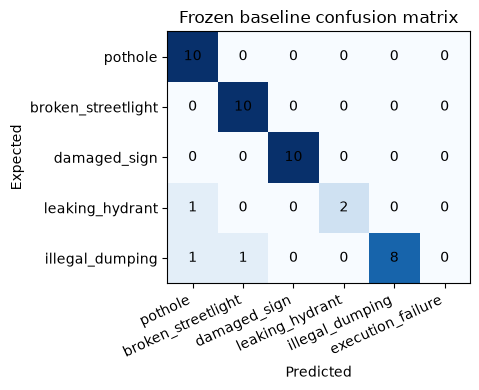

Latency seconds: {'mean': 0.03965478195256532, 'median': 0.0403874579933472, 'p95': 0.05080613689788151, 'maximum': 0.06567287500365637}
First image: 0.04109099999186583 | text prototype setup: 0.1924030420195777
Under 10 seconds: 43 / 43


In [5]:
def show_metrics(metrics,title):
    print(title, f"{metrics['correct']}/{metrics['attempted_n']} = {metrics['accuracy']:.2%}; macro-F1 {metrics['macro_f1']:.4f}")
    display(pd.DataFrame(metrics['per_class']).set_index('category'))
    matrix=pd.DataFrame(metrics['confusion_matrix'],index=CATEGORIES,columns=metrics['confusion_columns'])
    display(matrix)
    fig,ax=plt.subplots(figsize=(9,4))
    ax.imshow(matrix.values,cmap='Blues',vmin=0)
    ax.set_xticks(range(6),matrix.columns,rotation=25,ha='right')
    ax.set_yticks(range(5),CATEGORIES)
    ax.set_xlabel('Predicted');ax.set_ylabel('Expected');ax.set_title(title+' confusion matrix')
    for i in range(5):
        for j in range(6):ax.text(j,i,str(matrix.iloc[i,j]),ha='center',va='center')
    fig.tight_layout();plt.show()
    print('Latency seconds:',metrics['latency_seconds'])
    print('First image:',metrics['first_image_seconds'],'| text prototype setup:',metrics['text_prototype_seconds'])
    print('Under 10 seconds:',metrics['under_10_seconds'],'/',metrics['attempted_n'])
show_metrics(baseline_metrics,'Frozen baseline')

## Error analysis
The review covers all three baseline mistakes, the two correct predictions with the smallest margins, and the remaining hydrant examples: seven cases. The table shows expected/predicted categories and score margins. Original labels are kept, including cases that depend on source captions.

In [6]:
truth=development.set_index('image_id').issue_type.to_dict()
joined=[{**r,'expected':truth[r['image_id']]} for r in baseline_rows]
errors=[r for r in joined if r['status']!='success' or r['predicted_category']!=r['expected']]
weak=sorted([r for r in joined if r not in errors],key=lambda r:r['top1_margin'])
review=(sorted(errors,key=lambda r:-r.get('top1_margin',0)) + weak)[:max(5,min(10,len(errors)))]
for r in joined:
    if r['expected']=='leaking_hydrant' and r not in review:review.append(r)
print('Misclassifications/failures:',len(errors),'| review cases including all hydrants:',len(review))
display(pd.DataFrame([{'image_id':r['image_id'],'expected':r['expected'],
                      'predicted':r.get('predicted_category'),'margin':r.get('top1_margin'),
                      'scores':r.get('scores')} for r in review]))
write_new(RUN_ROOT/'review_ids.json',[r['image_id'] for r in review])
print('Baseline complete. Review images before selecting one targeted change.')

Misclassifications/failures: 3 | review cases including all hydrants: 7


,image_id,expected,predicted,margin,scores
0,commons-d5575814f4,leaking_hydrant,pothole,0.049593,"{'pothole': 0.31073760986328125, 'broken_streetlight': 0.21899516880512238, 'damaged_sign': 0.26..."
1,commons-7b78ffad33,illegal_dumping,pothole,0.013744,"{'pothole': 0.2739783227443695, 'broken_streetlight': 0.23963682353496552, 'damaged_sign': 0.256..."
2,commons-d374fa7f87,illegal_dumping,broken_streetlight,0.012641,"{'pothole': 0.22801189124584198, 'broken_streetlight': 0.25419533252716064, 'damaged_sign': 0.22..."
3,commons-9763aaca53,broken_streetlight,broken_streetlight,0.006528,"{'pothole': 0.2623370289802551, 'broken_streetlight': 0.3000379204750061, 'damaged_sign': 0.2914..."
4,commons-359e62bbe5,illegal_dumping,illegal_dumping,0.008518,"{'pothole': 0.26217490434646606, 'broken_streetlight': 0.27537328004837036, 'damaged_sign': 0.28..."
5,commons-1b000da556,leaking_hydrant,leaking_hydrant,0.013369,"{'pothole': 0.29485371708869934, 'broken_streetlight': 0.2665270268917084, 'damaged_sign': 0.279..."
6,commons-d86039e488,leaking_hydrant,leaking_hydrant,0.118174,"{'pothole': 0.21803468465805054, 'broken_streetlight': 0.20716506242752075, 'damaged_sign': 0.20..."


Baseline complete. Review images before selecting one targeted change.


### What the errors suggest
The missed hydrant photo shows a wet lane with no visible hydrant. Its margin, about 0.0496, is the largest among the wrong predictions: a larger margin does not guarantee a correct answer.

The two missed dumping photos show scattered branches and a discarded appliance. The original descriptions focus on piles of rubbish. The next run broadens only the dumping descriptions, expecting to improve those cases, with a risk of confusing other broken objects with waste.

In [7]:
review_notes=json.loads((HERE/'error_review.json').read_text())
review_map={r['image_id']:r for r in joined}
review_table=[]
for note in review_notes['cases']:
    r=review_map[note['image_id']]
    review_table.append({**note,'expected':r['expected'],'predicted':r['predicted_category'],
                        'top1_cosine':max(r['scores'].values()),'margin':r['top1_margin']})
display(pd.DataFrame(review_table))
print('Practical constraint: CPU batch-1 latency; original target is 10 seconds for 95/100 requests at each load.')
print('Measured baseline under 10 seconds:',baseline_metrics['under_10_seconds'],'/',baseline_metrics['attempted_n'])
print('Local inference excludes transfer/queue/app generation; no service SLA or final accuracy target is verified.')

,image_id,observation,possible_cause,expected,predicted,top1_cosine,margin
0,commons-d5575814f4,Water covers a lane; no hydrant body is visible.,Caption-dependent ground truth is not identifiable from these pixels. Largest wrong margin among...,leaking_hydrant,pothole,0.310738,0.049593
1,commons-7b78ffad33,Branches and scattered debris lie across abandoned pavement; waste is spread out rather than a c...,Road texture competes with sparse garden-waste evidence; baseline dumping prompts overemphasize ...,illegal_dumping,pothole,0.273978,0.013744
2,commons-d374fa7f87,A large discarded appliance rests beside vegetation; no intact streetlight is visible.,Single bulky appliance is under-described by pile-focused prompts; metal housing may resemble fi...,illegal_dumping,broken_streetlight,0.254195,0.012641
3,commons-9763aaca53,Fallen metal lamp/post components lie on paving. Correct but the top-two margin is small.,Broken metal hardware overlaps the visual appearance of signposts and dumped objects.,broken_streetlight,broken_streetlight,0.300038,0.006528
4,commons-359e62bbe5,Bulky furniture and debris sit beside a damaged road. Correct with a small margin.,Pothole-like road texture competes with waste in a wide scene; original center crop may lose per...,illegal_dumping,illegal_dumping,0.290879,0.008518
5,commons-1b000da556,Water emerges from a pavement opening; no exposed hydrant body. Correct category but source cont...,A correct forced-choice prediction does not demonstrate recognition of an unseen hydrant or the ...,leaking_hydrant,leaking_hydrant,0.308223,0.013369
6,commons-d86039e488,A visible hydrant has a tall water plume. Correct and a larger margin than the caption-dependent...,This is the clearest visual hydrant example; one clear case cannot establish generalization.,leaking_hydrant,leaking_hydrant,0.336209,0.118174


Practical constraint: CPU batch-1 latency; original target is 10 seconds for 95/100 requests at each load.
Measured baseline under 10 seconds: 43 / 43
Local inference excludes transfer/queue/app generation; no service SLA or final accuracy target is verified.


## Targeted change
Only the three `illegal_dumping` descriptions change. The other prompts, checkpoint, preprocessing, scoring, metrics, seed, CPU settings and 43 images stay fixed. The revised prompts and expected benefit are saved before the second run.

The second run reuses the loaded model, so small latency differences should not be attributed to the prompt change.

{
  "changed_variable": "illegal_dumping text descriptions only",
  "baseline_configuration_sha256": "de6c0f34d4c33b14489d7781ebc0cd519f14b9cb4389c0442c9fb269d495cbf9",
  "expected_benefit": "Better recognition of a single abandoned appliance and scattered garden waste; may confuse structural debris.",
  "held_fixed": "checkpoint, four other prompt sets, three prompts/category, image IDs/order, transforms, scoring, metrics, CPU/float32/batch/threads/seed",
  "registered_before_revision_inference": true,
  "revision_prompts": {
    "version": "v2-dumping-visual-coverage",
    "prompts": {
      "pothole": [
        "A photo of a pothole in an asphalt road.",
        "A photo of missing pavement forming a hole in a road surface.",
        "A photo of a damaged road surface with a pothole."
      ],
      "broken_streetlight": [
        "A photo of a damaged streetlight fixture.",
        "A photo of a broken streetlight pole or lamp.",
        "A photo of a streetlight with visible struc

Same-data, same-metric, one-variable comparison: PASS
Revised frozen configuration: f1e666ae7d6bb524ee015e3366d7171395a7e1bff6fcd388f5f06acda8cfb7d8
Dumping-prompt revision 41/43 = 95.35%; macro-F1 0.9304


,precision,recall,f1,support,correct
category,,,,,
pothole,0.909091,1.000000,0.952381,10,10
broken_streetlight,1.000000,1.000000,1.000000,10,10
damaged_sign,0.909091,1.000000,0.952381,10,10
leaking_hydrant,1.000000,0.666667,0.800000,3,2
illegal_dumping,1.000000,0.900000,0.947368,10,9


,pothole,broken_streetlight,damaged_sign,leaking_hydrant,illegal_dumping,execution_failure
pothole,10,0,0,0,0,0
broken_streetlight,0,10,0,0,0,0
damaged_sign,0,0,10,0,0,0
leaking_hydrant,1,0,0,2,0,0
illegal_dumping,0,0,1,0,9,0


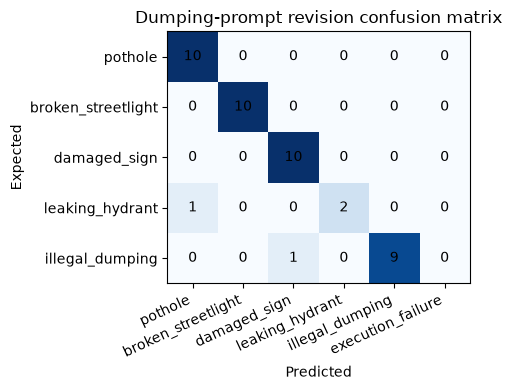

Latency seconds: {'mean': 0.03925270248856937, 'median': 0.0397017500072252, 'p95': 0.048465645808028056, 'maximum': 0.05190812499495223}
First image: 0.03298962500412017 | text prototype setup: 0.14734308299375698
Under 10 seconds: 43 / 43


,image_id,status,predicted_category,top1_margin,latency_seconds,pothole,broken_streetlight,damaged_sign,leaking_hydrant,illegal_dumping
0,commons-04258228ae,success,damaged_sign,0.074337,0.032990,0.230991,0.203898,0.305328,0.148661,0.218580
1,commons-0a68e3b438,success,pothole,0.028746,0.038956,0.330434,0.301688,0.281791,0.265747,0.251225
2,commons-0f02ab33ca,success,illegal_dumping,0.040112,0.031699,0.207142,0.227462,0.246653,0.169867,0.286766
3,commons-1b000da556,success,leaking_hydrant,0.013369,0.030976,0.294854,0.266527,0.279302,0.308223,0.262641
4,commons-1be7ba9610,success,damaged_sign,0.043131,0.033634,0.260078,0.267627,0.310758,0.213668,0.267323
5,commons-1ce17d43d9,success,illegal_dumping,0.028936,0.031383,0.225072,0.242423,0.248749,0.209844,0.277686
6,commons-2409b4bbcb,success,broken_streetlight,0.064957,0.039634,0.168848,0.305442,0.240485,0.224369,0.190461
7,commons-289e64dab5,success,damaged_sign,0.051651,0.031185,0.224491,0.247198,0.318801,0.223411,0.267150
8,commons-359e62bbe5,success,illegal_dumping,0.035480,0.032042,0.262175,0.275373,0.282361,0.227579,0.317841
9,commons-3e69e554ed,success,pothole,0.076136,0.040916,0.363261,0.283015,0.287126,0.261293,0.225085


In [8]:
prompts_v2=load_prompts(HERE/'prompts/categories.v2.json')
changed=[k for k in CATEGORIES if prompts_v1['prompts'][k]!=prompts_v2['prompts'][k]]
assert changed==['illegal_dumping']
hypothesis={'changed_variable':'illegal_dumping text descriptions only',
            'baseline_configuration_sha256':baseline_cfg['configuration_sha256'],
            'expected_benefit':'Better recognition of a single abandoned appliance and scattered garden waste; may confuse structural debris.',
            'held_fixed':'checkpoint, four other prompt sets, three prompts/category, image IDs/order, transforms, scoring, metrics, CPU/float32/batch/threads/seed',
            'registered_before_revision_inference':True,
            'revision_prompts':prompts_v2}
write_new(RUN_ROOT/'targeted_change_before_run.json',hypothesis)
print(json.dumps(hypothesis,indent=2))
revision_cfg,revision_rows,revision_metrics=run(runtime,development,split,
    HERE/'prompts/categories.v2.json',RUN_ROOT/'revision')
assert_one_change(baseline_cfg,revision_cfg)
assert [r['image_id'] for r in baseline_rows]==[r['image_id'] for r in revision_rows]
print('Same-data, same-metric, one-variable comparison: PASS')
print('Revised frozen configuration:',revision_cfg['configuration_sha256'])
show_metrics(revision_metrics,'Dumping-prompt revision')
display(pd.DataFrame([{**{k:r.get(k) for k in ['image_id','status','predicted_category','top1_margin','latency_seconds']},
                      **r.get('scores',{})} for r in revision_rows]))

## Experiment comparison
Both runs below use the same 43 development photos. The comparison includes the score, number of examples, failures, latency and service cost, followed by the predictions that changed.

In [9]:
def experiment_row(name,cfg,metrics,change):
    return {'run':name,'model':'ViT-B-32 / openai / fp32 CPU','prompt_version':cfg['prompts']['version'],
            'change':change,'correct/N':f"{metrics['correct']}/{metrics['attempted_n']}",
            'accuracy':metrics['accuracy'],'macro_F1':metrics['macro_f1'],
            'N':metrics['attempted_n'],'failures':metrics['failures'],
            'latency_mean_s':metrics['latency_seconds']['mean'],'latency_p95_s':metrics['latency_seconds']['p95'],
            'service_USD':0}
comparison=pd.DataFrame([experiment_row('baseline',baseline_cfg,baseline_metrics,'none'),
                        experiment_row('revision',revision_cfg,revision_metrics,'dumping text only')])
display(comparison)
changes=[]
for left,right in zip(joined,revision_rows):
    if left.get('predicted_category')!=right.get('predicted_category'):
        changes.append({'image_id':left['image_id'],'expected':left['expected'],
                        'baseline':left.get('predicted_category'),'revision':right.get('predicted_category'),
                        'baseline_correct':left.get('predicted_category')==left['expected'],
                        'revision_correct':right.get('predicted_category')==left['expected']})
display(pd.DataFrame(changes))
delta=revision_metrics['accuracy']-baseline_metrics['accuracy']
f1_delta=revision_metrics['macro_f1']-baseline_metrics['macro_f1']
outcome='helped on these development cases' if delta>0 and f1_delta>0 else ('hurt on these development cases' if delta<0 and f1_delta<0 else 'mixed or no clear improvement')
print(f'Outcome: {outcome}; accuracy delta {delta:+.2%}; macro-F1 delta {f1_delta:+.4f}.')
print('Remaining revised errors:',[r['image_id'] for r in revision_rows
      if r['status']!='success' or r.get('predicted_category')!=truth[r['image_id']]])
print('External socket connection attempts during notebook:',len(network_attempts))
assert not network_attempts
# Save the comparison separately from the raw prediction files.
safe_summary={'dataset':{k:inspection[k] for k in ['dataset_version','dataset_commit','manifest_sha256','pool_n','development_n']},
              'baseline':{'configuration':baseline_cfg,'metrics':baseline_metrics},
              'revision':{'configuration':revision_cfg,'metrics':revision_metrics},
              'comparison':comparison.to_dict(orient='records'),'changed_predictions':changes,
              'outcome':outcome,'external_socket_attempts':len(network_attempts),
              'limitations':['development set reused after error analysis','agent-curated labels',
                             '3 hydrants, 2 caption-dependent','mostly daylight/nonlocal photos',
                             'unknown overlap with original CLIP pretraining',
                             'closed-set classifier has no irrelevant-image rejection',
                             'no final held-out or concurrency/load evaluation','CPU local timing excludes full app workflow']}
write_new(RUN_ROOT/'safe_summary.json',safe_summary)
print('Safe summary saved; publication export is a separate reviewed H6 step.')

,run,model,prompt_version,change,correct/N,accuracy,macro_F1,N,failures,latency_mean_s,latency_p95_s,service_USD
0,baseline,ViT-B-32 / openai / fp32 CPU,v1,none,40/43,0.930233,0.910072,43,0,0.039655,0.050806,0
1,revision,ViT-B-32 / openai / fp32 CPU,v2-dumping-visual-coverage,dumping text only,41/43,0.953488,0.930426,43,0,0.039253,0.048466,0


,image_id,expected,baseline,revision,baseline_correct,revision_correct
0,commons-7b78ffad33,illegal_dumping,pothole,illegal_dumping,False,True
1,commons-d374fa7f87,illegal_dumping,broken_streetlight,illegal_dumping,False,True
2,commons-dca2e40d63,illegal_dumping,illegal_dumping,damaged_sign,True,False


Outcome: helped on these development cases; accuracy delta +2.33%; macro-F1 delta +0.0204.
Remaining revised errors: ['commons-d5575814f4', 'commons-dca2e40d63']
External socket connection attempts during notebook: 0
Safe summary saved; publication export is a separate reviewed H6 step.


## Limitations and next steps
The sample is small, mostly daylight and outside Gainesville. Two of the three hydrant labels depend on captions, and overlap with CLIP's original pretraining data is unknown. The center crop can also remove useful detail.

CLIP always picks one of the five categories, even for unrelated images. Photos alone cannot establish dumping legality or an electrical fault.

The next evaluation needs separate photos, including unclear and unrelated cases. Qwen descriptions and the reporting workflow will be tested later. Rerun commands are in the [experiment README](README.md).

## Final results

**The revised prompts got 41 of 43 photos correct (95.35%), compared with 40 of 43 (93.02%) for the baseline.**

| Run | Prompt change | Correct | Accuracy | Macro-F1 | Mean time per photo |
| --- | --- | ---: | ---: | ---: | ---: |
| Baseline | None | 40/43 | 93.02% | 0.9101 | 39.65 ms |
| Revised | Dumping descriptions only | 41/43 | 95.35% | 0.9304 | 39.25 ms |

**Results by category**

| Category | Baseline correct | Revised correct |
| --- | ---: | ---: |
| Pothole | 10/10 | 10/10 |
| Broken streetlight | 10/10 | 10/10 |
| Damaged sign | 10/10 | 10/10 |
| Leaking hydrant | 2/3 | 2/3 |
| Illegal dumping | 8/10 | 9/10 |

The change fixed the discarded-appliance and scattered-branches errors, but introduced one mistake on a rubble photo. That is a net gain of **one correct prediction**, or **2.33 percentage points**, with macro-F1 increasing from **0.9101 to 0.9304**. The wet-lane hydrant photo remained incorrect.

Both runs processed all 43 images with **zero execution failures** and **$0 in service charges**. Mean time was about 40 ms per photo on the Mac CPU, excluding model setup and the full app workflow. This does not establish the 100-request timing target.

The result supports keeping the revised prompts for the next evaluation, but a separate test set is needed before claiming better performance on new photos. Classification was explored first because pretrained CLIP provided a simple baseline on the available hardware. This experiment does not evaluate report descriptions or destination routing.
